In [1]:
import urllib.request
import zipfile
from pathlib import Path

import pandas as pd

url = "https://archive.ics.uci.edu/static/public/179/secom.zip"
data_dir = Path("secom")
data_dir.mkdir(exist_ok=True)
zip_path = data_dir / "secom.zip"

# Download (só se ainda não existir)
if not zip_path.exists():
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as resp, open(zip_path, "wb") as f:
        f.write(resp.read())

# Descompactar
with zipfile.ZipFile(zip_path) as z:
    z.extractall(data_dir)

# Sensores (1567 amostras x 590 variáveis; valores ausentes aparecem como "NaN")
df = pd.read_csv(
    data_dir / "secom.data",
    sep=r"\s+",
    header=None,
    na_values="NaN",
)
df.columns = [f"sensor_{i:03d}" for i in range(df.shape[1])]

# Rótulos (-1 = passou, 1 = falhou) e timestamp de cada amostra
labels = pd.read_csv(
    data_dir / "secom_labels.data",
    sep=" ",
    header=None,
    names=["label", "timestamp"],
)
labels["timestamp"] = pd.to_datetime(labels["timestamp"], format="%d/%m/%Y %H:%M:%S")

df = pd.concat([labels, df], axis=1)

print(df.shape)
df.head()

(1567, 592)


,label,timestamp,sensor_000,sensor_001,sensor_002,sensor_003,sensor_004,sensor_005,sensor_006,sensor_007,...,sensor_580,sensor_581,sensor_582,sensor_583,sensor_584,sensor_585,sensor_586,sensor_587,sensor_588,sensor_589
0,-1,2008-07-19 11:55:00,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,...,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,-1,2008-07-19 12:32:00,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,...,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,1,2008-07-19 13:17:00,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,-1,2008-07-19 14:43:00,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,...,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,-1,2008-07-19 15:22:00,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,...,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432


In [2]:
df.isna().mean().sort_values(ascending=False)

sensor_158    0.911934
sensor_157    0.911934
sensor_293    0.911934
sensor_292    0.911934
sensor_492    0.855775
                ...   
sensor_020    0.000000
sensor_570    0.000000
sensor_571    0.000000
sensor_572    0.000000
sensor_573    0.000000
Length: 592, dtype: float64

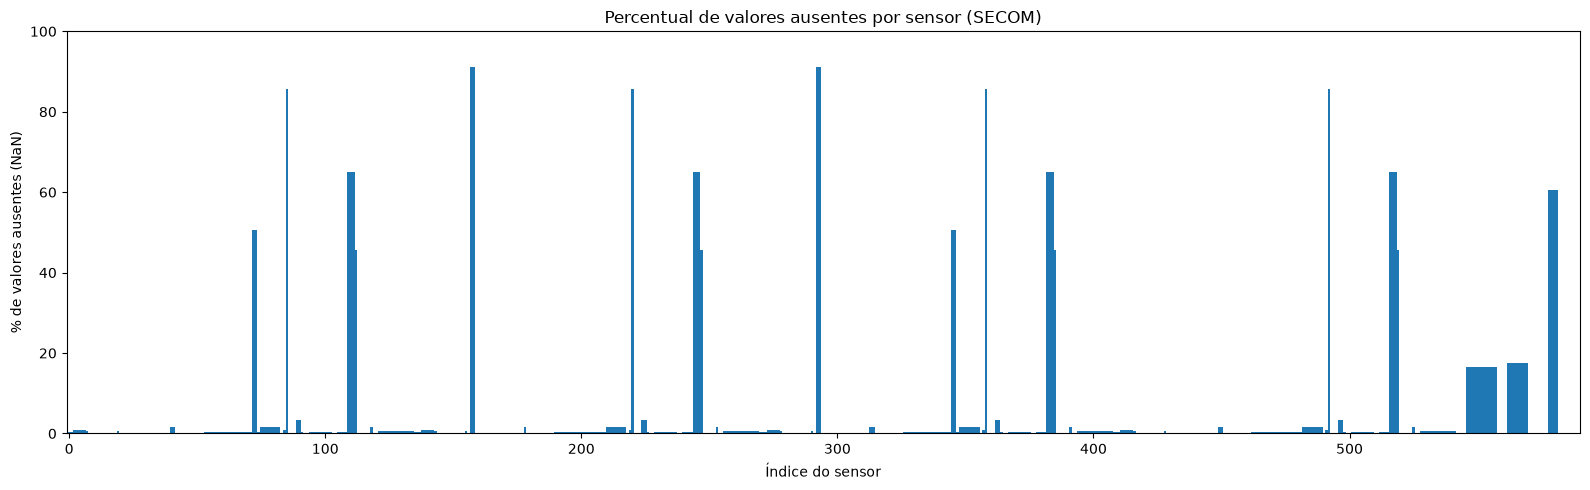

In [8]:
import matplotlib.pyplot as plt

# Percentual de NaN por sensor, mantendo a ordem original (sensor_000 ... sensor_589)
sensor_cols = [c for c in df.columns if c.startswith("sensor_")]
nan_pct = df[sensor_cols].isna().mean() * 100

fig, ax = plt.subplots(figsize=(16, 5))
ax.bar(range(len(nan_pct)), nan_pct.values, width=1.0)

ax.set_xlabel("Índice do sensor")
ax.set_ylabel("% de valores ausentes (NaN)")
ax.set_title("Percentual de valores ausentes por sensor (SECOM)")
ax.set_xlim(-1, len(nan_pct))
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

# Visão geral

O SECOM (Semiconductor Manufacturing) reúne dados de monitoramento de um processo de fabricação de semicondutores, coletados por sensores e outros pontos de medição ao longo da linha de produção. É um dataset multivariado, com 1567 amostras (cada uma corresponde a uma unidade de produção, como um lote ou wafer) e 590 variáveis numéricas contínuas. Os dados cobrem aproximadamente de julho a outubro de 2008.

## Variáveis
- Atributos (590): sinais de processo, sem nome nem unidade. Eles são anônimos, então não dá para saber a que grandeza física cada um corresponde (temperatura, pressão, vazão etc.). Isso limita a interpretação física dos resultados.
- Rótulo: -1 para unidade aprovada (1463 amostras) e 1 para reprovada (104 amostras), com base em um teste interno de linha (in-house line testing).
- Timestamp: data e hora associadas a cada amostra, que permitem análises temporais e validação em ordem cronológica.

## Objetivos

O problema central é de controle de qualidade e rendimento (yield):

1. Identificar quais sinais do processo estão mais relacionados às falhas, ou seja, seleção de variáveis.
2. Construir um classificador que preveja se uma unidade passará ou falhará no teste, a partir dos sinais do processo.
3. Com isso, reduzir custos e aumentar o rendimento, detectando desvios do processo antes ou sem depender de testes caros.

## Principais desafios
- Alta dimensionalidade: 590 variáveis para apenas 104 exemplos da classe de falha.
- Desbalanceamento: cerca de 6,6% de falhas, o que torna a acurácia uma métrica enganosa. Métricas como recall, F1, AUC-PR e MCC são mais adequadas.
- Valores ausentes: muitos sensores têm lacunas, alguns com mais de 90% de NaN, como você viu no gráfico.
- Colunas constantes ou quase constantes: um número considerável de sensores não varia (em torno de 116, segundo a literatura), e podem ser descartados. Dá para conferir com (df.nunique() <= 1).sum().
- Ruído e redundância: muitas variáveis são correlacionadas entre si.
- Deriva temporal: o processo muda ao longo do tempo, então um split aleatório pode dar resultados otimistas. Vale validar usando o timestamp (treino no passado, teste no futuro).

In [10]:
(df.nunique() <= 1).sum()

np.int64(116)